#### 1. Dataset Information

- **Title/Topic:** Insurance Factors

- **Source:** [Kaggle – Healthcare Insurance](https://www.kaggle.com/datasets/willianoliveiragibin/healthcare-insurance)

- **Real-World Context/Purpose:**  
  This dataset contains information about individuals and their healthcare insurance costs. It includes variables such as age, sex, BMI, number of children, smoking status, region, and insurance charges. The purpose of the dataset is to explore how these factors are related to healthcare insurance costs and identify patterns that may help predict insurance charges. The question we are asking here: Can health and lifestyle factors be used to predict the cost of health insurance?

#### 2. Basic Data Exploration

In [28]:
import numpy as np
import pandas as pd

df = pd.read_csv("insurance_factors.csv")
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [29]:
df.head(5)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [30]:
df.tail(5)

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [31]:
print("Number of rows and columns", df.shape)

Number of rows and columns (1338, 7)


In [32]:
print("Columns:", df.columns.tolist())

Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


#### Data Types and Structure


In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [34]:
categorical_columns = df.select_dtypes(include='str').columns
print("\nCategorical:")
categorical_columns


Categorical:


Index(['sex', 'smoker', 'region'], dtype='str')

In [35]:
numerical_columns = df.select_dtypes(include='number').columns
print("Numerical columns:")
numerical_columns

Numerical columns:


Index(['age', 'bmi', 'children', 'charges'], dtype='str')

In [36]:
df.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

No data type conversion is required because the numerical columns are already stored as numeric data types, and the categorical columns are appropriately stored as object/string types.

#### 4. Descriptive Summary

In [37]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [38]:
# Examinining descriptive statistics and identify potentially unusual values
numerical_columns = ['age', 'bmi', 'children', 'charges']

summary = df[numerical_columns].describe().T
display(summary[['min', 'max', 'mean', 'std']])

# Unusually high insurance charges
print("\nPotentially unusual charges:")
display(df[df['charges'] > df['charges'].mean() + 2 * df['charges'].std()])

,min,max,mean,std
age,18.0000,64.00000,39.207025,14.049960
bmi,15.9600,53.13000,30.663397,6.098187
children,0.0000,5.00000,1.094918,1.205493
charges,1121.8739,63770.42801,13270.422265,12110.011237



Potentially unusual charges:


,age,sex,bmi,children,smoker,region,charges
14,27,male,42.130,0,yes,southeast,39611.75770
23,34,female,31.920,1,yes,northeast,37701.87680
29,31,male,36.300,2,yes,southwest,38711.00000
34,28,male,36.400,1,yes,southwest,51194.55914
38,35,male,36.670,1,yes,northeast,39774.27630
...,...,...,...,...,...,...,...
1288,20,male,39.400,2,yes,southwest,38344.56600
1300,45,male,30.360,0,yes,southeast,62592.87309
1301,62,male,30.875,3,yes,northwest,46718.16325
1303,43,male,27.800,0,yes,southwest,37829.72420


#### 5. Missing and Duplicate Data

In [39]:
print("Missing values:\n", df.isnull().sum())

Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


There are no missing values.

In [40]:
df.duplicated().sum()
print(df[df.duplicated()])

     age   sex    bmi  children smoker     region    charges
581   19  male  30.59         0     no  northwest  1639.5631


There is one duplicate row which is the 582nd row 

The dataset contains 1,338 observations, with numerical variables including age, BMI, children, and insurance charges. The average age is 39.21 years, while the average BMI is 30.66 and the average number of children is 1.09. Insurance charges have an average of 13,270.42 and range from 1,121.87 to 63,770.43. The large difference between the mean and maximum charge suggests that some individuals have unusually high insurance costs that may influence the analysis.

##### Checking for typos

In [41]:
df['sex'].unique()


<ArrowStringArray>
['female', 'male']
Length: 2, dtype: str

In [42]:
df['smoker'].unique()


<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str

In [43]:
df['region'].unique()

<ArrowStringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str

There are no typos

---

### Part A: Additional observations for the assignment checklist

*The cells above are my original in-class activity. I kept them unchanged and added these short clarifications to cover the remaining explanatory details in the project instructions.*

- **Column types:** The numerical columns are `age`, `bmi`, `children`, and `charges`. The categorical columns are `sex`, `smoker`, and `region`. The numerical fields are already stored as numbers, and the categories are stored as text, so no conversion appears necessary for these analyses.
- **Interpreting the summary statistics:** The insurance charges range from about **1,121.87 to 63,770.43**, with a mean of **13,270.42**, a median of **$9,382.03**, and a standard deviation of about **12,110.01**. The large standard deviation shows considerable variation in charges; the mean being higher than the median suggests that a smaller number of large charges raise the average. The BMI standard deviation is about **6.10**, showing that BMI also varies across people.
- **Missing and duplicate data:** There are **no missing values** in the original columns, so missing entries do not reduce the number of usable observations. There is **one duplicate row**, which could give one repeated observation extra influence if not addressed. I would investigate it before deciding whether to remove it; I have not silently changed the dataset.
- **Additional quality check:** The displayed categories for `sex`, `smoker`, and `region` show no obvious inconsistent labels. This does not necessarily rule out every possible issue in the numerical data.

In [44]:
# Explicitly display the duplicate count; the in-class code above already shows the row.
print('Number of duplicate rows:', df.duplicated().sum())

Number of duplicate rows: 1


---

## PART B — DATA WRANGLING

### 6. Add New Calculated Columns Using Existing Data

**Question:** Among **smokers only**, do people with above-average BMI also tend to have above-average insurance charges?

I created two numerical columns by subtracting the average value **among smokers** from each person's existing value:

- `bmi_difference` = person's BMI − average BMI among smokers.
- `charge_difference` = person's charges − average charges among smokers.

A positive difference means the value is above the smoker-group average; a negative difference means it is below that average. A BMI difference of +2 means the person's BMI is 2 units above the average BMI for smokers. The charge difference is measured in dollars; for example, +2000 means $2,000 above the smoker-group average. These are **differences from an average**, not changes over time. Using the same reference category makes the subsequent comparison consistent.

In [45]:
# Calculate reference averages using smokers only.
smoker_reference = df[df['smoker'] == 'yes']
smoker_mean_bmi = smoker_reference['bmi'].mean()
smoker_mean_charges = smoker_reference['charges'].mean()

# New numerical columns using the existing BMI and insurance-charge data.
df['bmi_difference'] = df['bmi'] - smoker_mean_bmi
df['charge_difference'] = df['charges'] - smoker_mean_charges

print(f'Average BMI among smokers: {smoker_mean_bmi:.2f}')
print(f'Average charges among smokers: ${smoker_mean_charges:,.2f}')
print('First five rows, confirming both calculated columns:')
display(df[['smoker', 'bmi', 'bmi_difference', 'charges', 'charge_difference']].head())

Average BMI among smokers: 30.71
Average charges among smokers: $32,050.23
First five rows, confirming both calculated columns:


,smoker,bmi,bmi_difference,charges,charge_difference
0,yes,27.900,-2.808449,16884.92400,-15165.307832
1,no,33.770,3.061551,1725.55230,-30324.679532
2,no,33.000,2.291551,4449.46200,-27600.769832
3,no,22.705,-8.003449,21984.47061,-10065.761222
4,no,28.880,-1.828449,3866.85520,-28183.376632


### 7. Filter the Data

**Filter 1: Smokers only:** I selected participants whose `smoker` value is `yes`. This is the single category used for the BMI-versus-insurance-charge correlation. Keeping smoking status fixed avoids mixing smokers and non-smokers, whose average charges can differ substantially.

In [46]:
# Filter 1: only smokers
smokers = df[df['smoker'] == 'yes'].copy()
print('Number of smokers:', len(smokers))
display(smokers[['age', 'bmi', 'charges', 'bmi_difference', 'charge_difference']].head(10))

Number of smokers: 274


,age,bmi,charges,bmi_difference,charge_difference
0,19,27.90,16884.92400,-2.808449,-15165.307832
11,62,26.29,27808.72510,-4.418449,-4241.506732
14,27,42.13,39611.75770,11.421551,7561.525868
19,30,35.30,36837.46700,4.591551,4787.235168
23,34,31.92,37701.87680,1.211551,5651.644968
29,31,36.30,38711.00000,5.591551,6660.768168
30,22,35.60,35585.57600,4.891551,3535.344168
34,28,36.40,51194.55914,5.691551,19144.327308
38,35,36.67,39774.27630,5.961551,7724.044468
39,60,39.90,48173.36100,9.191551,16123.129168


**Filter 2: People aged 50 or older:** I separately selected participants aged 50+. This filter examines the role of age rather than repeating the smoking filter or the new BMI calculation. Some participants can belong to both subsets; **only the smokers subset** is used for the main correlation.

In [47]:
# Filter 2: age 50 or older, regardless of smoking status.
older_adults = df[df['age'] >= 50].copy()
print('Number of participants aged 50 or older:', len(older_adults))
display(older_adults[['age', 'smoker', 'bmi', 'charges']].head(10))

Number of participants aged 50 or older: 385


,age,smoker,bmi,charges
9,60,no,25.840,28923.13692
11,62,yes,26.290,27808.72510
13,56,no,39.820,11090.71780
16,52,no,30.780,10797.33620
18,56,no,40.300,10602.38500
20,60,no,36.005,13228.84695
25,59,no,27.720,14001.13380
26,63,no,23.085,14451.83515
27,55,no,32.775,12268.63225
33,63,no,28.310,13770.09790


### 8. Unique Values and Categories

The categorical variables are `sex`, `smoker`, and `region`. **Smoking status** is important because I focus the correlation on smokers only, and **region** is useful for grouping the smoker subset in Section 9. `sex` could also be useful for later comparisons. The new difference columns are numerical, not categorical.

In [48]:
# Display all distinct values in the original categorical columns.
for column in ['sex', 'smoker', 'region']:
    print(f'{column}: {df[column].unique().tolist()}')

sex: ['female', 'male']
smoker: ['yes', 'no']
region: ['southwest', 'southeast', 'northwest', 'northeast']


### 9. Grouping and Aggregation

I grouped **smokers only** by `region`, an existing categorical variable. For each region, I calculated the count, mean BMI, and mean charges. This helps me see variation in charges within the smoker category rather than mixing smoking categories.

In [25]:
# Group and summarize the smokers subset by region.
smoker_region_summary = (
    smokers.groupby('region')
           .agg(
               count=('charges', 'size'),
               average_bmi=('bmi', 'mean'),
               average_charges=('charges', 'mean')
           )
           .round(2)
)
display(smoker_region_summary)

# State concrete comparisons using the calculated table.
highest_region = smoker_region_summary['average_charges'].idxmax()
lowest_region = smoker_region_summary['average_charges'].idxmin()
print(f'Among smokers, {highest_region} has the highest average charges '
      f'(${smoker_region_summary.loc[highest_region, "average_charges"]:,.2f}).')
print(f'Among smokers, {lowest_region} has the lowest average charges '
      f'(${smoker_region_summary.loc[lowest_region, "average_charges"]:,.2f}).')

,count,average_bmi,average_charges
region,,,
northeast,67,28.57,29673.54
northwest,58,29.14,30192.00
southeast,91,33.10,34845.00
southwest,58,31.01,32269.06


Among smokers, southeast has the highest average charges ($34,845.00).
Among smokers, northeast has the lowest average charges ($29,673.54).


**Interpretation (2–3 sentences):** The table compares average insurance charges across the four regions **within the smoker group**; the printed results identify the highest and lowest regional averages. The `count` column shows how many smokers contribute to each mean, which is important because a smaller group might be less representative. Any regional differences are descriptive and do not prove that region itself causes changes in charges.

#### Additional analysis: Correlation between BMI difference and charge difference

To answer my main question, I calculated the **Pearson correlation coefficient** between the two calculated columns **among smokers only**. A positive coefficient means above-average BMI tends to go along with above-average charges in this subset; a negative coefficient means the opposite. A coefficient near zero suggests little linear association. A scatter plot helps visualize the relationship and identify unusual observations.

In [26]:
# This correlation uses just one smoking category: smokers.
correlation = smokers['bmi_difference'].corr(smokers['charge_difference'])
print(f'Pearson correlation among smokers: r = {correlation:.3f}')

if pd.isna(correlation):
    print('There is not enough variation to estimate a correlation.')
elif correlation > 0:
    print('The observed linear association is positive.')
elif correlation < 0:
    print('The observed linear association is negative.')
else:
    print('No linear association is detected by this measure.')
print('Correlation measures association and does not establish causation.')

Pearson correlation among smokers: r = 0.806
The observed linear association is positive.
Correlation measures association and does not establish causation.


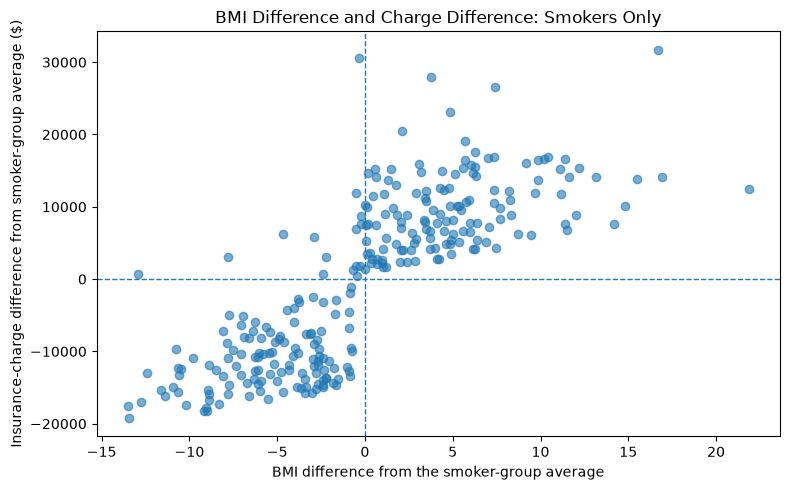

In [27]:
# Scatter plot of the two new columns, using smokers only.
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(smokers['bmi_difference'], smokers['charge_difference'], alpha=0.6)
plt.axhline(0, linestyle='--', linewidth=1)
plt.axvline(0, linestyle='--', linewidth=1)
plt.xlabel('BMI difference from the smoker-group average')
plt.ylabel('Insurance-charge difference from smoker-group average ($)')
plt.title('BMI Difference and Charge Difference: Smokers Only')
plt.tight_layout()
plt.show()

Subtracting the group averages centers the values around zero, but **does not change the Pearson correlation**. In the smoker subset, the correlation of `bmi_difference` with `charge_difference` is the same as the correlation of the original `bmi` with `charges`. The difference columns are useful for expressing how far individuals are above or below the chosen reference averages, not for producing a different `r`. Other factors such as age may still affect the observed relationship.

---

## PART C: SUMMARY AND CONCLUSION

### 10. Initial Observations

The original dataset contains **1,338 observations** and shows considerable variation in insurance charges. The mean charge is about **13,270**, while the median is about **9,382**, and the maximum is approximately **63,770**. This suggests the average may be influenced by people with much higher charges than others. The data contains **no missing values**, but **one duplicate row** was found and should be reviewed before doing further analysis.

For the data-wrangling section, I created two numerical columns showing how far each person's BMI and charges are from the corresponding averages **among smokers**. I then filtered the data to study **smokers only**, because comparing people within one smoking category gives a more focused view of the BMI–charge relationship. The correlation and scatter plot help answer whether higher-than-average BMI tends to accompany higher-than-average charges in this subgroup. I also filtered people aged 50 or older as a separate example and grouped smokers by region to compare their average charges.

I found it interesting that we can use simple calculations, filtering, and grouping to ask more specific questions than the overall dataset averages can answer. **I would interpret the actual calculated correlation and regional averages after running all cells on the complete CSV**, rather than assuming that BMI causes changes in insurance charges. In further analysis, I would examine age and other variables that might help explain the differences.

### Additional Insights

**1. Why use the smoker-group average?** Both new columns use averages calculated from smokers, so zero represents the same reference group for each measure. The signs of the differences then show whether each smoker is above or below the smoker-group averages.

**2. Why use a single category?** Comparing only smokers avoids combining two groups that may have very different insurance-charge distributions. It does not, however, control for differences in age, BMI or region *among* smokers.

**3. Why keep the scatter plot?** Pearson's `r` gives one number describing a linear trend, but the plot can show curved patterns, clusters or extreme values that the coefficient alone may hide.

**4. Why review data quality?** A duplicate observation may influence the statistics, while extremely high charges can strongly affect means and correlation. Neither should automatically be deleted without investigation.

**5. What might be investigated next?** A future project could compare smokers and non-smokers in separate analyses, examine age groups, or use a regression model to account for several factors at once. For this assignment, I kept the main correlation specifically within the smoker category.